# Credit Risk Modeling Engine

## Quantitative Credit Risk Analysis

This notebook presents an integrated credit-risk framework implemented in Python. The analysis combines traditional expected-loss measures, statistical credit scoring, rating migrations, correlated-default simulation, portfolio concentration, Credit VaR, Expected Shortfall, economic capital, and stress testing.

### Main objectives

1. Calculate Probability of Default (PD), Loss Given Default (LGD), and Exposure at Default (EAD).
2. Estimate expected and unexpected credit losses.
3. Train a logistic-regression credit-scoring model.
4. Analyze credit-rating migrations using Markov chains.
5. Simulate correlated defaults with Monte Carlo methods.
6. Measure Credit VaR, Expected Shortfall, and economic capital.
7. Evaluate borrower and sector concentration.
8. Assess portfolio vulnerability under adverse economic scenarios.

**Author:** Alexander Carrillo Reyes  
**Project:** Credit Risk Modeling Engine  
**Language:** Python 3.14

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.datasets import make_classification

# Locate the project root so the src package can be imported.
current_path = Path.cwd().resolve()
project_root = next(
    (
        path
        for path in (current_path, *current_path.parents)
        if (path / "src").is_dir()
    ),
    None,
)

if project_root is None:
    raise RuntimeError("The project root could not be located.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.credit_scoring import (
    get_model_coefficients,
    train_credit_scoring_model,
)
from src.default_simulation import (
    create_credit_portfolio,
    simulate_correlated_defaults,
)
from src.expected_loss import (
    CreditExposure,
    calculate_credit_risk_metrics,
    calculate_portfolio_credit_risk,
)
from src.portfolio_risk import (
    StressScenario,
    analyze_portfolio_risk,
    run_stress_scenarios,
)
from src.transition_matrix import (
    calculate_default_probability,
    create_transition_model,
    project_rating_distribution,
)
from src.visualization import (
    plot_exposure_contributions,
    plot_loss_distribution,
    plot_sector_risk,
    plot_stress_testing,
    plot_transition_heatmap,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.6f}".format)

print(f"Python executable: {sys.executable}")
print(f"Project root: {project_root}")
print("Credit-risk modules imported successfully.")

Python executable: c:\Users\Admin\Documents\Utech\Proyectos\credit-risk-modeling-engine\.venv\Scripts\python.exe
Project root: C:\Users\Admin\Documents\Utech\Proyectos\credit-risk-modeling-engine
Credit-risk modules imported successfully.


## 1. Fundamental Credit Risk Measures

Credit risk is the possibility that a borrower fails to meet a contractual financial obligation. Three fundamental parameters describe the potential loss associated with each exposure.

### Probability of Default — PD

The Probability of Default measures the likelihood that borrower \(i\) defaults during the selected risk horizon:

\[
PD_i = P(D_i = 1)
\]

where \(D_i\) is a Bernoulli default indicator.

### Loss Given Default — LGD

Loss Given Default represents the proportion of the exposure that cannot be recovered after default:

\[
LGD_i = 1 - RR_i
\]

where \(RR_i\) is the recovery rate.

### Exposure at Default — EAD

Exposure at Default is the monetary amount outstanding when default occurs.

### Expected Loss

Expected Loss represents the average credit loss anticipated over many comparable periods:

\[
EL_i = PD_i \times LGD_i \times EAD_i
\]

For a portfolio containing \(N\) exposures:

\[
EL_P = \sum_{i=1}^{N} PD_i \times LGD_i \times EAD_i
\]

### Unexpected Loss

Under a Bernoulli default model with deterministic LGD and EAD:

\[
UL_i =
LGD_i \times EAD_i
\times
\sqrt{PD_i(1-PD_i)}
\]

Assuming independent defaults, portfolio unexpected loss is:

\[
UL_P =
\sqrt{
\sum_{i=1}^{N} UL_i^2
}
\]

Expected Loss is generally covered through pricing and provisions, while Unexpected Loss is associated with economic capital.

In [2]:
credit_exposures = [
    CreditExposure(
        identifier="Corporate_A",
        probability_of_default=0.010,
        loss_given_default=0.40,
        exposure_at_default=2_000_000.0,
    ),
    CreditExposure(
        identifier="Corporate_B",
        probability_of_default=0.015,
        loss_given_default=0.45,
        exposure_at_default=1_500_000.0,
    ),
    CreditExposure(
        identifier="Retail_A",
        probability_of_default=0.025,
        loss_given_default=0.45,
        exposure_at_default=1_200_000.0,
    ),
    CreditExposure(
        identifier="Retail_B",
        probability_of_default=0.035,
        loss_given_default=0.50,
        exposure_at_default=900_000.0,
    ),
    CreditExposure(
        identifier="RealEstate_A",
        probability_of_default=0.050,
        loss_given_default=0.55,
        exposure_at_default=750_000.0,
    ),
    CreditExposure(
        identifier="RealEstate_B",
        probability_of_default=0.060,
        loss_given_default=0.50,
        exposure_at_default=600_000.0,
    ),
    CreditExposure(
        identifier="Technology_A",
        probability_of_default=0.080,
        loss_given_default=0.60,
        exposure_at_default=400_000.0,
    ),
    CreditExposure(
        identifier="Technology_B",
        probability_of_default=0.100,
        loss_given_default=0.65,
        exposure_at_default=300_000.0,
    ),
]

exposure_rows = []

for exposure in credit_exposures:
    metrics = calculate_credit_risk_metrics(
        probability_of_default=exposure.probability_of_default,
        loss_given_default=exposure.loss_given_default,
        exposure_at_default=exposure.exposure_at_default,
    )

    exposure_rows.append(
        {
            "Exposure": exposure.identifier,
            "PD": exposure.probability_of_default,
            "LGD": exposure.loss_given_default,
            "EAD": exposure.exposure_at_default,
            "Expected Loss": metrics.expected_loss,
            "Unexpected Loss": metrics.unexpected_loss,
            "Maximum Loss": metrics.maximum_loss,
        }
    )

exposure_table = pd.DataFrame(exposure_rows)

display(
    exposure_table.style.format(
        {
            "PD": "{:.2%}",
            "LGD": "{:.2%}",
            "EAD": "${:,.2f}",
            "Expected Loss": "${:,.2f}",
            "Unexpected Loss": "${:,.2f}",
            "Maximum Loss": "${:,.2f}",
        }
    )
)

portfolio_fundamentals = calculate_portfolio_credit_risk(
    credit_exposures
)

portfolio_summary = pd.DataFrame(
    {
        "Metric": [
            "Number of exposures",
            "Total exposure",
            "Expected loss",
            "Unexpected loss",
            "Maximum loss",
        ],
        "Value": [
            portfolio_fundamentals.exposure_count,
            portfolio_fundamentals.total_exposure,
            portfolio_fundamentals.expected_loss,
            portfolio_fundamentals.unexpected_loss,
            portfolio_fundamentals.maximum_loss,
        ],
    }
)

display(portfolio_summary)

,Exposure,PD,LGD,EAD,Expected Loss,Unexpected Loss,Maximum Loss
0,Corporate_A,1.00%,40.00%,"$2,000,000.00","$8,000.00","$79,598.99","$800,000.00"
1,Corporate_B,1.50%,45.00%,"$1,500,000.00","$10,125.00","$82,047.91","$675,000.00"
2,Retail_A,2.50%,45.00%,"$1,200,000.00","$13,500.00","$84,307.47","$540,000.00"
3,Retail_B,3.50%,50.00%,"$900,000.00","$15,750.00","$82,700.89","$450,000.00"
4,RealEstate_A,5.00%,55.00%,"$750,000.00","$20,625.00","$89,902.29","$412,500.00"
5,RealEstate_B,6.00%,50.00%,"$600,000.00","$18,000.00","$71,246.05","$300,000.00"
6,Technology_A,8.00%,60.00%,"$400,000.00","$19,200.00","$65,110.37","$240,000.00"
7,Technology_B,10.00%,65.00%,"$300,000.00","$19,500.00","$58,500.00","$195,000.00"


,Metric,Value
0,Number of exposures,8.000000
1,Total exposure,"7,650,000.000000"
2,Expected loss,"124,700.000000"
3,Unexpected loss,"218,712.319612"
4,Maximum loss,"3,612,500.000000"


## 2. Credit Scoring with Logistic Regression

A credit-scoring model estimates the probability that a borrower defaults based on financial and behavioral characteristics.

For borrower \(i\), the logistic model defines a linear score:

\[
z_i =
\beta_0
+
\beta_1 x_{i1}
+
\beta_2 x_{i2}
+\cdots+
\beta_k x_{ik}
\]

The score is transformed into a probability using the logistic function:

\[
PD_i =
\frac{1}
{1 + e^{-z_i}}
\]

The resulting probability always remains between zero and one.

The explanatory variables used in this analysis are:

- income stability;
- debt-to-income ratio;
- payment history;
- credit utilization;
- account age.

Positive coefficients increase estimated default risk, while negative coefficients reduce it.

### Model evaluation

The model is evaluated using:

- **Accuracy:** proportion of correctly classified borrowers.
- **Precision:** proportion of predicted defaults that actually defaulted.
- **Recall:** proportion of actual defaults detected by the model.
- **F1 score:** harmonic mean of precision and recall.
- **ROC AUC:** ability to rank risky borrowers above safer borrowers.
- **Brier score:** mean squared error of the predicted probabilities.

A larger ROC AUC is desirable, while a smaller Brier score indicates better probability calibration.

In [3]:
random_generator = np.random.default_rng(42)
borrower_count = 4_000

income_stability = random_generator.beta(
    5.0,
    2.0,
    borrower_count,
)
debt_to_income = random_generator.beta(
    2.0,
    4.0,
    borrower_count,
)
payment_history = random_generator.beta(
    6.0,
    2.0,
    borrower_count,
)
credit_utilization = random_generator.beta(
    2.5,
    3.0,
    borrower_count,
)
account_age = random_generator.beta(
    2.0,
    2.0,
    borrower_count,
)

borrower_features = np.column_stack(
    [
        income_stability,
        debt_to_income,
        payment_history,
        credit_utilization,
        account_age,
    ]
)

feature_names = (
    "Income stability",
    "Debt-to-income ratio",
    "Payment history",
    "Credit utilization",
    "Account age",
)

latent_default_score = (
    -2.50
    - 1.20 * income_stability
    + 2.20 * debt_to_income
    - 2.00 * payment_history
    + 1.80 * credit_utilization
    - 0.50 * account_age
)

true_default_probabilities = 1.0 / (
    1.0 + np.exp(-latent_default_score)
)

default_target = random_generator.binomial(
    n=1,
    p=true_default_probabilities,
)

scoring_result = train_credit_scoring_model(
    features=borrower_features,
    target=default_target,
    feature_names=feature_names,
    test_size=0.25,
    default_threshold=0.50,
    random_state=42,
)

scoring_metrics = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1 score",
            "ROC AUC",
            "Brier score",
            "Portfolio default rate",
        ],
        "Value": [
            scoring_result.metrics.accuracy,
            scoring_result.metrics.precision,
            scoring_result.metrics.recall,
            scoring_result.metrics.f1_score,
            scoring_result.metrics.roc_auc,
            scoring_result.metrics.brier_score,
            scoring_result.default_rate,
        ],
    }
)

display(
    scoring_metrics.style.format(
        {"Value": "{:.4f}"}
    )
)

coefficient_table = (
    pd.DataFrame(
        {
            "Feature": list(
                get_model_coefficients(
                    scoring_result.model
                ).keys()
            ),
            "Standardized coefficient": list(
                get_model_coefficients(
                    scoring_result.model
                ).values()
            ),
        }
    )
    .sort_values(
        "Standardized coefficient",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    coefficient_table.style.format(
        {"Standardized coefficient": "{:+.6f}"}
    )
)

,Metric,Value
0,Accuracy,0.9660
1,Precision,0.0000
2,Recall,0.0000
3,F1 score,0.0000
4,ROC AUC,0.6170
5,Brier score,0.0326
6,Portfolio default rate,0.0338


,Feature,Standardized coefficient
0,Credit utilization,+0.450605
1,Debt-to-income ratio,+0.416572
2,Income stability,-0.246248
3,Payment history,-0.309898
4,Account age,-0.362672


## 3. Credit Rating Transitions and Markov Chains

Credit quality is not constant. A borrower may remain in the same rating, migrate to a better rating, deteriorate to a lower rating, or enter default.

A transition matrix \(P\) contains the one-period migration probabilities:

\[
P =
\begin{bmatrix}
p_{11} & p_{12} & \cdots & p_{1K} \\
p_{21} & p_{22} & \cdots & p_{2K} \\
\vdots & \vdots & \ddots & \vdots \\
p_{K1} & p_{K2} & \cdots & p_{KK}
\end{bmatrix}
\]

Each element is defined as:

\[
p_{ij}
=
P(R_{t+1}=j \mid R_t=i)
\]

Every row must satisfy:

\[
\sum_{j=1}^{K} p_{ij} = 1
\]

The model assumes the Markov property: the next rating depends on the current rating and not on the complete historical path.

### Multi-period transitions

The transition matrix after \(n\) periods is:

\[
P^{(n)} = P^n
\]

The cumulative default probability for a borrower currently rated \(i\) is obtained from the default column:

\[
PD_i^{(n)}
=
\left[P^n\right]_{i,D}
\]

Default is modeled as an absorbing state:

\[
P(D \rightarrow D)=1
\]

Once a borrower defaults, the model does not allow migration back to a performing rating.

,Rating,One-year PD,Five-year cumulative PD
0,AAA,0.00%,0.13%
1,AA,0.00%,0.50%
2,A,0.10%,1.71%
3,BBB,0.50%,6.31%
4,BB,2.50%,17.25%
5,B,10.00%,36.45%


,Rating,Initial distribution,Five-year distribution
0,AAA,5.00%,4.28%
1,AA,10.00%,10.82%
2,A,25.00%,20.18%
3,BBB,30.00%,21.83%
4,BB,15.00%,16.91%
5,B,15.00%,15.54%
6,Default,0.00%,10.43%


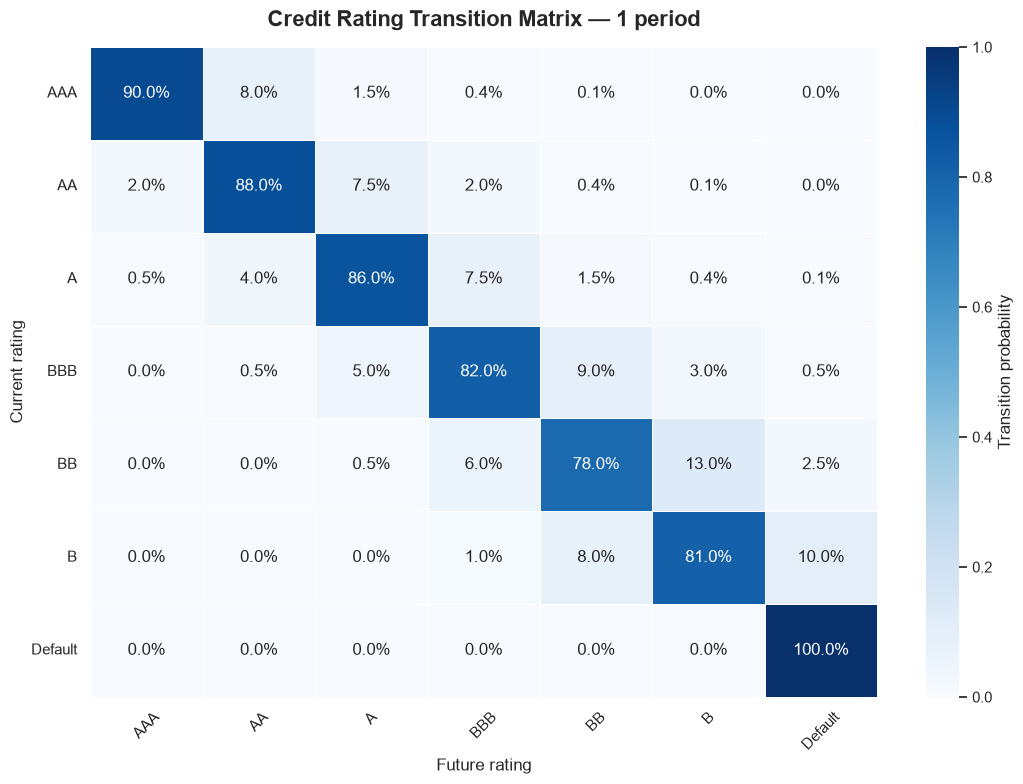

In [4]:
ratings = (
    "AAA",
    "AA",
    "A",
    "BBB",
    "BB",
    "B",
    "Default",
)

annual_transition_matrix = np.array(
    [
        [0.900, 0.080, 0.015, 0.004, 0.001, 0.000, 0.000],
        [0.020, 0.880, 0.075, 0.020, 0.004, 0.001, 0.000],
        [0.005, 0.040, 0.860, 0.075, 0.015, 0.004, 0.001],
        [0.000, 0.005, 0.050, 0.820, 0.090, 0.030, 0.005],
        [0.000, 0.000, 0.005, 0.060, 0.780, 0.130, 0.025],
        [0.000, 0.000, 0.000, 0.010, 0.080, 0.810, 0.100],
        [0.000, 0.000, 0.000, 0.000, 0.000, 0.000, 1.000],
    ]
)

transition_model = create_transition_model(
    ratings=ratings,
    transition_matrix=annual_transition_matrix,
)

default_probability_table = pd.DataFrame(
    {
        "Rating": ratings[:-1],
        "One-year PD": [
            calculate_default_probability(
                model=transition_model,
                initial_rating=rating,
                periods=1,
            )
            for rating in ratings[:-1]
        ],
        "Five-year cumulative PD": [
            calculate_default_probability(
                model=transition_model,
                initial_rating=rating,
                periods=5,
            )
            for rating in ratings[:-1]
        ],
    }
)

display(
    default_probability_table.style.format(
        {
            "One-year PD": "{:.2%}",
            "Five-year cumulative PD": "{:.2%}",
        }
    )
)

initial_rating_distribution = np.array(
    [0.05, 0.10, 0.25, 0.30, 0.15, 0.15, 0.00]
)

five_year_distribution = project_rating_distribution(
    model=transition_model,
    initial_distribution=initial_rating_distribution,
    periods=5,
)

distribution_table = pd.DataFrame(
    {
        "Rating": ratings,
        "Initial distribution": initial_rating_distribution,
        "Five-year distribution": five_year_distribution,
    }
)

display(
    distribution_table.style.format(
        {
            "Initial distribution": "{:.2%}",
            "Five-year distribution": "{:.2%}",
        }
    )
)

plot_transition_heatmap(
    model=transition_model,
    periods=1,
)

plt.show()

## 4. Correlated Default Simulation

Borrower defaults are not completely independent. During an economic recession, many borrowers may experience financial stress simultaneously.

The one-factor Gaussian credit model represents the latent credit condition of borrower \(i\) in simulation \(s\) as:

\[
Z_{s,i}
=
\sqrt{\rho}\,Y_s
+
\sqrt{1-\rho}\,\varepsilon_{s,i}
\]

where:

- \(Y_s \sim N(0,1)\) is the common systematic economic factor;
- \(\varepsilon_{s,i} \sim N(0,1)\) is the borrower-specific factor;
- \(\rho\) is the asset correlation.

A borrower defaults when:

\[
Z_{s,i}
<
\Phi^{-1}(PD_i)
\]

where \(\Phi^{-1}\) is the inverse standard normal distribution.

The loss produced by borrower \(i\) is:

\[
L_{s,i}
=
D_{s,i}
\times LGD_i
\times EAD_i
\]

The total portfolio loss in simulation \(s\) is:

\[
L_s
=
\sum_{i=1}^{N} L_{s,i}
\]

### Credit Value at Risk

At confidence level \(\alpha\), Credit VaR is the corresponding loss quantile:

\[
CreditVaR_{\alpha}
=
\inf
\left\{
l:
P(L \leq l) \geq \alpha
\right\}
\]

### Expected Shortfall

Expected Shortfall measures the average loss in the extreme tail:

\[
ES_{\alpha}
=
E
\left[
L
\mid
L \geq CreditVaR_{\alpha}
\right]
\]

### Economic Capital

Economic capital covers unexpected losses beyond the average expected loss:

\[
EC_{\alpha}
=
CreditVaR_{\alpha}
-
EL
\]

,Metric,Value
0,Number of simulations,"100,000.000000"
1,Asset correlation,0.200000
2,Confidence level,0.990000
3,Analytical expected loss,"124,700.000000"
4,Simulated expected loss,"126,159.450000"
5,Loss standard deviation,"254,151.911969"
6,Credit VaR,"1,147,500.000000"
7,Expected Shortfall,"1,431,976.915521"
8,Economic capital,"1,022,800.000000"
9,Maximum simulated loss,"2,937,500.000000"


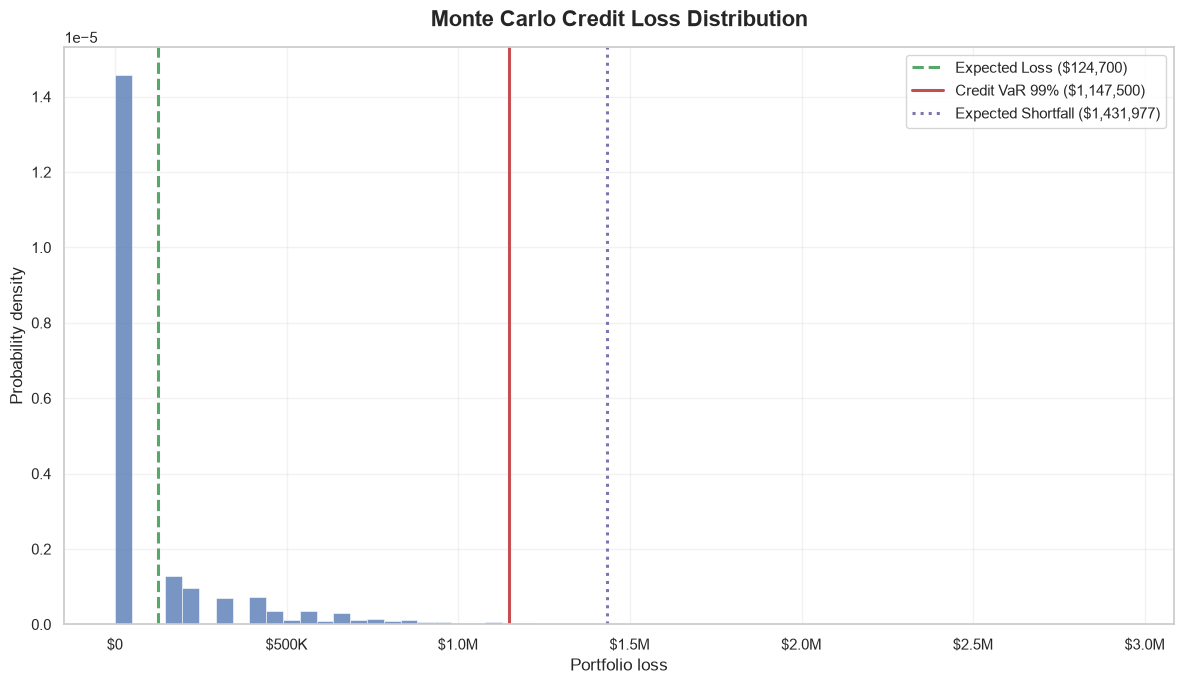

In [5]:
simulation_portfolio = create_credit_portfolio(
    probabilities_of_default=[
        exposure.probability_of_default
        for exposure in credit_exposures
    ],
    losses_given_default=[
        exposure.loss_given_default
        for exposure in credit_exposures
    ],
    exposures_at_default=[
        exposure.exposure_at_default
        for exposure in credit_exposures
    ],
    identifiers=[
        exposure.identifier
        for exposure in credit_exposures
    ],
)

simulation_result = simulate_correlated_defaults(
    portfolio=simulation_portfolio,
    number_of_simulations=100_000,
    asset_correlation=0.20,
    confidence_level=0.99,
    random_state=42,
)

simulation_summary = pd.DataFrame(
    {
        "Metric": [
            "Number of simulations",
            "Asset correlation",
            "Confidence level",
            "Analytical expected loss",
            "Simulated expected loss",
            "Loss standard deviation",
            "Credit VaR",
            "Expected Shortfall",
            "Economic capital",
            "Maximum simulated loss",
            "Average default count",
            "Maximum default count",
        ],
        "Value": [
            simulation_result.number_of_simulations,
            simulation_result.asset_correlation,
            simulation_result.confidence_level,
            simulation_result.analytical_expected_loss,
            simulation_result.simulated_expected_loss,
            simulation_result.loss_standard_deviation,
            simulation_result.value_at_risk,
            simulation_result.expected_shortfall,
            simulation_result.economic_capital,
            simulation_result.maximum_simulated_loss,
            simulation_result.average_default_count,
            simulation_result.maximum_default_count,
        ],
    }
)

display(simulation_summary)

plot_loss_distribution(
    result=simulation_result,
    bins=60,
)

plt.show()

## 5. Portfolio Concentration and Stress Testing

A credit portfolio can appear diversified while still containing excessive exposure to a small number of borrowers or economic sectors.

### Exposure shares

The exposure share of borrower \(i\) is:

\[
w_i =
\frac{EAD_i}
{\sum_{j=1}^{N} EAD_j}
\]

### Herfindahl–Hirschman Index

The HHI measures borrower concentration:

\[
HHI =
\sum_{i=1}^{N} w_i^2
\]

For an equally weighted portfolio:

\[
HHI_{\min} = \frac{1}{N}
\]

The normalized concentration index is:

\[
HHI_{\text{normalized}}
=
\frac{
HHI-\frac{1}{N}
}{
1-\frac{1}{N}
}
\]

A value close to zero indicates a more evenly distributed portfolio, while a value close to one indicates strong concentration.

### Expected-loss contribution

The expected-loss contribution of borrower \(i\) is:

\[
ELC_i =
\frac{EL_i}
{\sum_{j=1}^{N} EL_j}
\]

A borrower may have a moderate exposure share but a large loss contribution because of a high PD or LGD.

### Stress testing

Stress scenarios modify the credit parameters:

\[
PD_i^{stress}
=
\min(PD_i \times m_{PD}, 1)
\]

\[
LGD_i^{stress}
=
\min(LGD_i \times m_{LGD}, 1)
\]

\[
EAD_i^{stress}
=
EAD_i \times m_{EAD}
\]

The stressed expected loss is then:

\[
EL^{stress}
=
\sum_{i=1}^{N}
PD_i^{stress}
\times
LGD_i^{stress}
\times
EAD_i^{stress}
\]

In [6]:
sectors = [
    "Corporate",
    "Corporate",
    "Retail",
    "Retail",
    "Real Estate",
    "Real Estate",
    "Technology",
    "Technology",
]

portfolio_analysis = analyze_portfolio_risk(
    portfolio=simulation_portfolio,
    sectors=sectors,
)

concentration_summary = pd.DataFrame(
    {
        "Metric": [
            "Exposure count",
            "Total exposure",
            "Expected loss",
            "Weighted-average PD",
            "Weighted-average LGD",
            "Largest exposure share",
            "HHI concentration",
            "Normalized concentration",
        ],
        "Value": [
            portfolio_analysis.exposure_count,
            portfolio_analysis.total_exposure,
            portfolio_analysis.expected_loss,
            portfolio_analysis.weighted_average_pd,
            portfolio_analysis.weighted_average_lgd,
            portfolio_analysis.largest_exposure_share,
            portfolio_analysis.herfindahl_hirschman_index,
            portfolio_analysis.normalized_concentration_index,
        ],
    }
)

display(concentration_summary)

sector_table = pd.DataFrame(
    [
        {
            "Sector": sector.sector,
            "Exposures": sector.exposure_count,
            "Total EAD": sector.total_exposure,
            "Expected Loss": sector.expected_loss,
            "EAD Share": sector.exposure_share,
            "EL Share": sector.expected_loss_share,
        }
        for sector in portfolio_analysis.sector_summaries
    ]
)

display(
    sector_table.style.format(
        {
            "Total EAD": "${:,.2f}",
            "Expected Loss": "${:,.2f}",
            "EAD Share": "{:.2%}",
            "EL Share": "{:.2%}",
        }
    )
)

stress_scenarios = [
    StressScenario(
        name="Mild slowdown",
        pd_multiplier=1.25,
        lgd_multiplier=1.05,
        ead_multiplier=1.00,
    ),
    StressScenario(
        name="Moderate recession",
        pd_multiplier=1.50,
        lgd_multiplier=1.10,
        ead_multiplier=1.02,
    ),
    StressScenario(
        name="Severe recession",
        pd_multiplier=2.50,
        lgd_multiplier=1.25,
        ead_multiplier=1.10,
    ),
]

stress_results = run_stress_scenarios(
    portfolio=simulation_portfolio,
    scenarios=stress_scenarios,
)

stress_table = pd.DataFrame(
    [
        {
            "Scenario": result.scenario.name,
            "Base Expected Loss": result.base_expected_loss,
            "Stressed Expected Loss": result.stressed_expected_loss,
            "Absolute Increase": result.absolute_increase,
            "Percentage Increase": result.percentage_increase,
        }
        for result in stress_results
    ]
)

display(
    stress_table.style.format(
        {
            "Base Expected Loss": "${:,.2f}",
            "Stressed Expected Loss": "${:,.2f}",
            "Absolute Increase": "${:,.2f}",
            "Percentage Increase": "{:.2%}",
        }
    )
)

,Metric,Value
0,Exposure count,8.000000
1,Total exposure,"7,650,000.000000"
2,Expected loss,"124,700.000000"
3,Weighted-average PD,0.031307
4,Weighted-average LGD,0.472222
5,Largest exposure share,0.261438
6,HHI concentration,0.165278
7,Normalized concentration,0.046032


,Sector,Exposures,Total EAD,Expected Loss,EAD Share,EL Share
0,Corporate,2,"$3,500,000.00","$18,125.00",45.75%,14.53%
1,Real Estate,2,"$1,350,000.00","$38,625.00",17.65%,30.97%
2,Retail,2,"$2,100,000.00","$29,250.00",27.45%,23.46%
3,Technology,2,"$700,000.00","$38,700.00",9.15%,31.03%


,Scenario,Base Expected Loss,Stressed Expected Loss,Absolute Increase,Percentage Increase
0,Mild slowdown,"$124,700.00","$163,668.75","$38,968.75",31.25%
1,Moderate recession,"$124,700.00","$209,870.10","$85,170.10",68.30%
2,Severe recession,"$124,700.00","$428,656.25","$303,956.25",243.75%


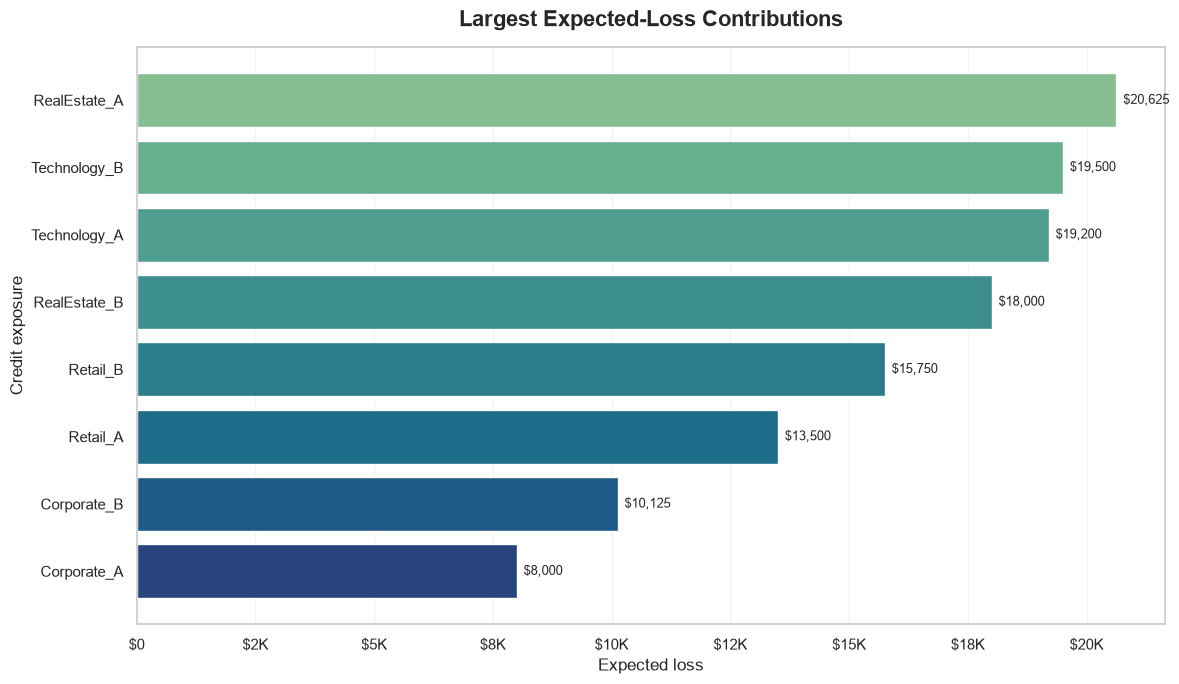

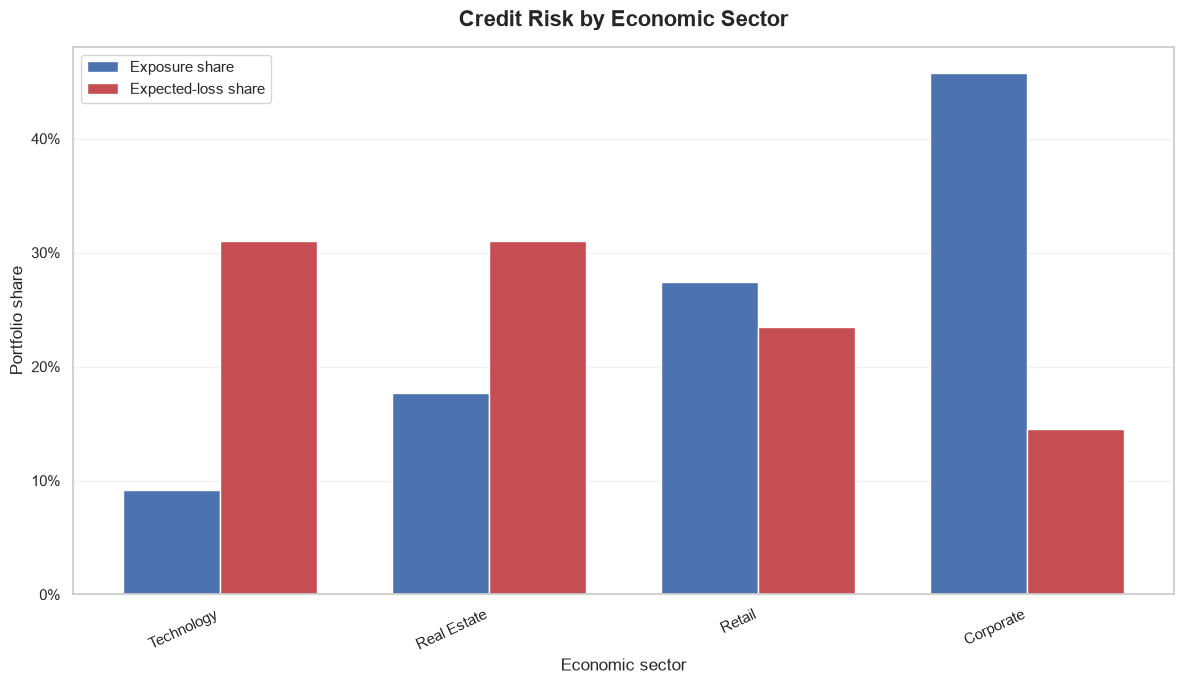

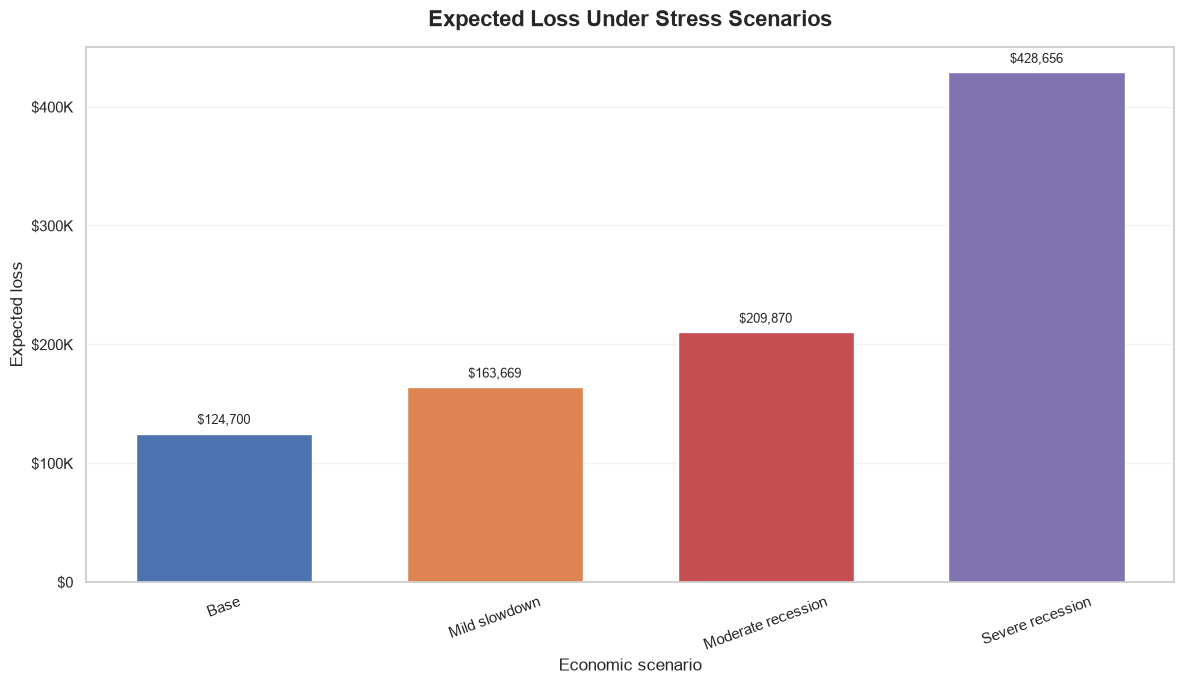

In [7]:
plot_exposure_contributions(
    analysis=portfolio_analysis,
    top_n=8,
)
plt.show()

plot_sector_risk(
    analysis=portfolio_analysis,
)
plt.show()

plot_stress_testing(
    results=stress_results,
)
plt.show()

## 6. Asset-Correlation Sensitivity

Default correlation is a major driver of portfolio tail risk.

When asset correlation is low, borrower defaults are primarily driven by individual circumstances. Diversification therefore reduces portfolio volatility.

When asset correlation increases, the common economic factor becomes more important. During an adverse economic scenario, several borrowers may default together.

The latent-variable model is:

\[
Z_i =
\sqrt{\rho}\,Y
+
\sqrt{1-\rho}\,\varepsilon_i
\]

As \(\rho\) increases:

- portfolio Expected Loss should remain relatively stable;
- loss volatility generally increases;
- Credit VaR increases;
- Expected Shortfall increases;
- economic capital requirements increase.

This occurs because correlation affects the concentration of losses in adverse scenarios rather than the individual unconditional PD values.

,Asset Correlation,Expected Loss,Loss Volatility,Credit VaR,Expected Shortfall,Economic Capital
0,0%,"$125,397.25","$218,613.75","$870,000.00","$1,050,630.76","$745,300.00"
1,10%,"$125,475.95","$234,760.47","$995,000.00","$1,225,270.67","$870,300.00"
2,20%,"$125,198.80","$252,972.70","$1,125,000.00","$1,416,257.40","$1,000,300.00"
3,35%,"$125,863.85","$285,941.39","$1,340,000.00","$1,737,807.62","$1,215,300.00"
4,50%,"$125,315.20","$325,136.73","$1,597,500.00","$2,101,605.81","$1,472,800.00"


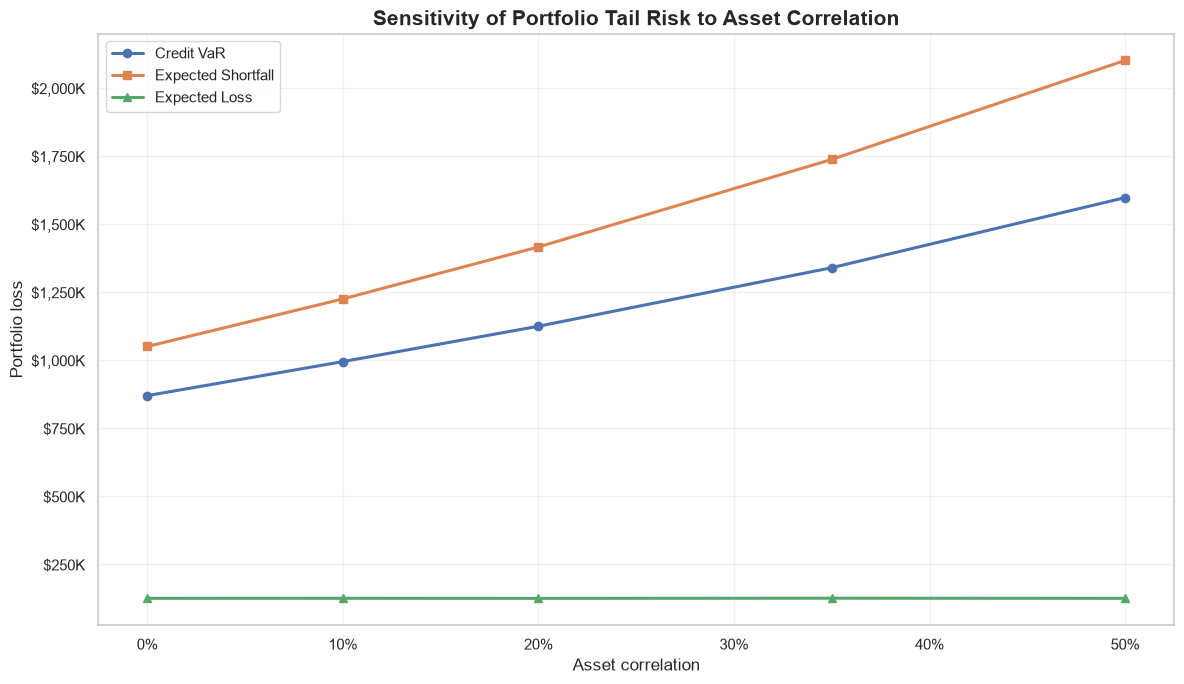

In [8]:
correlation_levels = [
    0.00,
    0.10,
    0.20,
    0.35,
    0.50,
]

correlation_results = []

for correlation in correlation_levels:
    result = simulate_correlated_defaults(
        portfolio=simulation_portfolio,
        number_of_simulations=50_000,
        asset_correlation=correlation,
        confidence_level=0.99,
        random_state=42,
    )

    correlation_results.append(
        {
            "Asset Correlation": correlation,
            "Expected Loss": result.simulated_expected_loss,
            "Loss Volatility": result.loss_standard_deviation,
            "Credit VaR": result.value_at_risk,
            "Expected Shortfall": result.expected_shortfall,
            "Economic Capital": result.economic_capital,
        }
    )

correlation_table = pd.DataFrame(correlation_results)

display(
    correlation_table.style.format(
        {
            "Asset Correlation": "{:.0%}",
            "Expected Loss": "${:,.2f}",
            "Loss Volatility": "${:,.2f}",
            "Credit VaR": "${:,.2f}",
            "Expected Shortfall": "${:,.2f}",
            "Economic Capital": "${:,.2f}",
        }
    )
)

figure, axis = plt.subplots(figsize=(12, 7))

axis.plot(
    correlation_table["Asset Correlation"],
    correlation_table["Credit VaR"],
    marker="o",
    linewidth=2.2,
    label="Credit VaR",
)
axis.plot(
    correlation_table["Asset Correlation"],
    correlation_table["Expected Shortfall"],
    marker="s",
    linewidth=2.2,
    label="Expected Shortfall",
)
axis.plot(
    correlation_table["Asset Correlation"],
    correlation_table["Expected Loss"],
    marker="^",
    linewidth=2.2,
    label="Expected Loss",
)

axis.set_title(
    "Sensitivity of Portfolio Tail Risk to Asset Correlation",
    fontsize=15,
    fontweight="bold",
)
axis.set_xlabel("Asset correlation")
axis.set_ylabel("Portfolio loss")
axis.xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, _position: f"{value:.0%}"
    )
)
axis.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, _position: f"${value / 1_000:,.0f}K"
    )
)
axis.legend()
axis.grid(alpha=0.25)

figure.tight_layout()
plt.show()

In [9]:
executive_summary = pd.DataFrame(
    {
        "Key Risk Indicator": [
            "Total credit exposure",
            "Analytical expected loss",
            "Expected loss rate",
            "Credit VaR at 99%",
            "Expected Shortfall at 99%",
            "Economic capital",
            "Weighted-average PD",
            "Weighted-average LGD",
            "Largest borrower share",
            "HHI concentration",
            "Severe recession expected loss",
        ],
        "Value": [
            f"${portfolio_analysis.total_exposure:,.2f}",
            f"${simulation_result.analytical_expected_loss:,.2f}",
            (
                f"{simulation_result.analytical_expected_loss / portfolio_analysis.total_exposure:.2%}"
            ),
            f"${simulation_result.value_at_risk:,.2f}",
            f"${simulation_result.expected_shortfall:,.2f}",
            f"${simulation_result.economic_capital:,.2f}",
            f"{portfolio_analysis.weighted_average_pd:.2%}",
            f"{portfolio_analysis.weighted_average_lgd:.2%}",
            f"{portfolio_analysis.largest_exposure_share:.2%}",
            f"{portfolio_analysis.herfindahl_hirschman_index:.6f}",
            f"${stress_results[-1].stressed_expected_loss:,.2f}",
        ],
    }
)

display(
    executive_summary.style.set_caption(
        "Executive Credit Risk Summary"
    )
)

,Key Risk Indicator,Value
0,Total credit exposure,"$7,650,000.00"
1,Analytical expected loss,"$124,700.00"
2,Expected loss rate,1.63%
3,Credit VaR at 99%,"$1,147,500.00"
4,Expected Shortfall at 99%,"$1,431,976.92"
5,Economic capital,"$1,022,800.00"
6,Weighted-average PD,3.13%
7,Weighted-average LGD,47.22%
8,Largest borrower share,26.14%
9,HHI concentration,0.165278


## 7. Conclusions

This analysis developed an integrated quantitative framework for measuring borrower-level and portfolio-level credit risk.

### Main findings

1. **Expected Loss** provides the average monetary loss implied by PD, LGD, and EAD.
2. **Unexpected Loss** measures uncertainty around the expected outcome and supports capital planning.
3. **Logistic regression** transforms borrower characteristics into interpretable probabilities of default.
4. **Rating-transition matrices** capture improvements, deterioration, and cumulative default probabilities through Markov chains.
5. **Monte Carlo simulation** produces the complete portfolio loss distribution rather than a single deterministic estimate.
6. **Credit VaR** identifies a high-confidence loss threshold.
7. **Expected Shortfall** measures the average severity of losses beyond Credit VaR.
8. **Economic capital** represents the capital buffer required above expected loss.
9. **HHI concentration** reveals whether portfolio exposure is dominated by a small number of borrowers.
10. **Sector analysis** identifies economic segments that contribute disproportionately to credit risk.
11. **Stress testing** measures portfolio vulnerability under adverse changes in PD, LGD, and EAD.
12. **Correlation sensitivity** demonstrates that systematic economic dependence increases tail risk even when average expected loss remains relatively stable.

### Model assumptions and limitations

The results depend on several simplifying assumptions:

- PD, LGD, and EAD are treated as known model inputs.
- LGD and EAD are deterministic within each simulation.
- Borrower dependence is represented by a single Gaussian systematic factor.
- Asset correlation is constant across borrowers.
- Rating migrations follow a time-homogeneous Markov process.
- The logistic-regression dataset is synthetic and designed for demonstration.
- Transition probabilities are illustrative rather than calibrated from proprietary bank data.
- Monte Carlo estimates contain sampling uncertainty.
- The framework does not include prepayment, cure rates, collateral price dynamics, or macroeconomic forecasting.

### Practical interpretation

In a real banking environment, this framework could support:

- loan pricing;
- credit approval;
- IFRS 9 or CECL provisioning;
- portfolio limits;
- sector concentration monitoring;
- stress testing;
- economic-capital allocation;
- risk-adjusted performance measurement;
- regulatory and management reporting.

---

**Disclaimer:** This project is an educational quantitative-finance simulation. It is not financial advice and should not be used as a production credit-decision system without independent validation, governance, calibration, and regulatory review.